In [2]:
from sklearn import *

# The Goal

You want to give your boss more than just a "good" model. You want to give him the set of "best" hyperparameters to use, as well as an indication of how performant (*e.g.* accurate) the resulting model will be.

# What makes a good model?

Predict the target outcome for new, unseen samples.

# What is data leakage?

Data leakage happens if data is available for training that is not available for prediction. This can be split into 2 classes:

- Target leakage:
  + Time series data, make sure you don't have data from the future available when doing training
  + Make sure your features are not derived from targets. For example, a dataset with target `has_pneumonia` and a feature `is_treated_for_pneumonia`. Most likely the feature is a result of the target. 
 
- Train-test contamination
  + See following code examples

In [3]:
data = datasets.load_digits()
raw_X = data.data
y = data.target
print(raw_X.shape, y.shape)

(1797, 64) (1797,)


In [4]:
scaler = preprocessing.StandardScaler()
X = scaler.fit_transform(raw_X)
model = ensemble.RandomForestClassifier()
model.fit(X, y)
yhat = model.predict(X) # Resubstitution
score = metrics.f1_score(y, yhat, average='micro')
print(score)

1.0


***

In [56]:
# Here we first scale the complete dataset before splitting it. This way the scaler learns about the
# test set!
scaler = preprocessing.StandardScaler()
X = scaler.fit_transform(raw_X)  # First scale
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y)  # Then split
model = ensemble.RandomForestClassifier()
model.fit(X_train, y_train)
yhat = model.predict(X_test)
score = metrics.f1_score(y_test, yhat, average='micro')
print(score)

0.9711111111111111


***

In [9]:
# This is pretty decent, but it's tedious because you need to manually
# feed data through your preprocessing and model, and make sure you don't forget one.

X_train, X_test, y_train, y_test = model_selection.train_test_split(raw_X, y)

scaler = preprocessing.StandardScaler()
X_train = scaler.fit_transform(X_train)
model = ensemble.RandomForestClassifier()

model.fit(X_train, y_train)

X_test = scaler.transform(X_test)  # Don't forget to also scale your test features!
yhat = model.predict(X_test)
score = metrics.f1_score(y_test, yhat, average='micro')
print(score)

0.9733333333333334


***

In [15]:
# Pipelines make it easy to chain Transformers and Estimators. The problem is that when hand-optimizing
# the hyperparameters, each time the cell is executed we get a new train/test split, meaning were actually
# "optimizing" which split we get...

X_train, X_test, y_train, y_test = model_selection.train_test_split(raw_X, y)

model = pipeline.make_pipeline(  # See also pipeline.Pipeline
    preprocessing.StandardScaler(),
    ensemble.RandomForestClassifier(
        n_estimators=25,
        criterion='gini',
        max_depth=10,
        min_samples_split=2,
        min_samples_leaf=1,
        min_weight_fraction_leaf=0.0,
        max_features=None,
        max_leaf_nodes=None,
        min_impurity_decrease=0.0,
    ),
)

model.fit(X_train, y_train)
yhat = model.predict(X_test)
score = metrics.f1_score(y_test, yhat, average='micro')
print(score)

0.9377777777777778


***

In [16]:
# Now we split in only once, in a separate cell
# Here the problem is that I cannot use the score to tune my hyperparameters, 
# because then the hyperparameters will eventually encode my testing data
X_train, X_test, y_train, y_test = model_selection.train_test_split(raw_X, y)

In [25]:
model = pipeline.make_pipeline(  # See also pipeline.Pipeline
    preprocessing.StandardScaler(),
    ensemble.RandomForestClassifier(
        n_estimators=200,
        criterion='gini',
        max_depth=10,
        min_samples_split=2,
        min_samples_leaf=2,
        min_weight_fraction_leaf=0.0,
        max_features="log2",
        max_leaf_nodes=None,
        min_impurity_decrease=0.0,
        random_state=42  # Random forests have a random element, fix it for the demo.
    ),
)

model.fit(X_train, y_train)
yhat = model.predict(X_test)
score = metrics.f1_score(y_test, yhat, average='micro')
print(score)

0.9777777777777777


***

# (Stratified) K-fold cross validation and hyperparameter optimisation

K-fold cross validation: split the *training*\* data into K folds. Pick one of the folds as validation set, and train a model on the others. Validate the performance of that model using the validation set. Do this for all K combinations and average the resulting scores.

Hyperparameters determine the behaviour of your model, for example the strength of the regularisation or the criterion used for determining splits in a tree. You want to optimize these to find the best possible model.

Stratified splits: Let's say you have 100 samples, 20 positive and 80 negative. If you then randomly draw 20 samples (for example for your test set), the chance of drawing 20 negative samples is non-zero. The solution is making sure you draw 20% of your positive samples and 20% of your negative samples, so that the distribution of classes in your test set is the same as in your total data. Usually, sklearn does the right thing.

\* Your test data is in a vault, so you can't use that

In [26]:
# Generate your train/test data, and put the test data in a vault.
X_train, X_test, y_train, y_test = model_selection.train_test_split(raw_X, y)

In [27]:
model = pipeline.make_pipeline(  # See also pipeline.Pipeline
    preprocessing.StandardScaler(),
    ensemble.RandomForestClassifier(),
)

from pprint import pprint
pprint(model.get_params())  # This shows the parameters we can play with. Not all are useful.

{'memory': None,
 'randomforestclassifier': RandomForestClassifier(),
 'randomforestclassifier__bootstrap': True,
 'randomforestclassifier__ccp_alpha': 0.0,
 'randomforestclassifier__class_weight': None,
 'randomforestclassifier__criterion': 'gini',
 'randomforestclassifier__max_depth': None,
 'randomforestclassifier__max_features': 'sqrt',
 'randomforestclassifier__max_leaf_nodes': None,
 'randomforestclassifier__max_samples': None,
 'randomforestclassifier__min_impurity_decrease': 0.0,
 'randomforestclassifier__min_samples_leaf': 1,
 'randomforestclassifier__min_samples_split': 2,
 'randomforestclassifier__min_weight_fraction_leaf': 0.0,
 'randomforestclassifier__monotonic_cst': None,
 'randomforestclassifier__n_estimators': 100,
 'randomforestclassifier__n_jobs': None,
 'randomforestclassifier__oob_score': False,
 'randomforestclassifier__random_state': None,
 'randomforestclassifier__verbose': 0,
 'randomforestclassifier__warm_start': False,
 'standardscaler': StandardScaler(),
 's

In [28]:
# This does a hyperparameter optimization. The objective function is determined by the 
# `scoring` argument, and the search space for the hyperparameters by the `param_grid`.
# The GridSearch algorithm just tries all possible combinations and returns the best.

# See also: RandomizedSearchCV, Halving(Grid|Randomized)SearchCV
gridsearch = model_selection.GridSearchCV(
    estimator=model,
    param_grid={
        'randomforestclassifier__n_estimators': [25, 50, 75, 100],
        'randomforestclassifier__criterion': ['gini', 'entropy'],
        'randomforestclassifier__max_depth': [None, 10],
        'randomforestclassifier__min_samples_split': [2],
        'randomforestclassifier__min_samples_leaf': [1],
        'randomforestclassifier__min_weight_fraction_leaf': [0.0],
        'randomforestclassifier__max_features': [None, "sqrt", "log2"],
        'randomforestclassifier__max_leaf_nodes': [None],
        'randomforestclassifier__min_impurity_decrease': [0.0],
    },
    cv=5,
    scoring=metrics.make_scorer(metrics.f1_score, average='micro'),
    n_jobs=-1,
)


gridsearch.fit(X_train, y_train)
best = gridsearch.best_estimator_
print(gridsearch.best_params_)
print(gridsearch.best_score_)
yhat = best.predict(X_test)
score = metrics.f1_score(y_test, yhat, average='micro')
print(score)

{'randomforestclassifier__criterion': 'entropy', 'randomforestclassifier__max_depth': None, 'randomforestclassifier__max_features': 'log2', 'randomforestclassifier__max_leaf_nodes': None, 'randomforestclassifier__min_impurity_decrease': 0.0, 'randomforestclassifier__min_samples_leaf': 1, 'randomforestclassifier__min_samples_split': 2, 'randomforestclassifier__min_weight_fraction_leaf': 0.0, 'randomforestclassifier__n_estimators': 50}
0.9732810133553628
0.9577777777777777


In [29]:
# Different classifier algorithms? Ugly hack incoming!
# Here, we explore the idea "what if the type of algorithm I use is a hyperparameter?"

model = pipeline.Pipeline([
    ('scale', preprocessing.StandardScaler()),
    ('clf', dummy.DummyClassifier()),
])

pprint(model.get_params())  # Note that 'clf' is one of the available parameters!

{'clf': DummyClassifier(),
 'clf__constant': None,
 'clf__random_state': None,
 'clf__strategy': 'prior',
 'memory': None,
 'scale': StandardScaler(),
 'scale__copy': True,
 'scale__with_mean': True,
 'scale__with_std': True,
 'steps': [('scale', StandardScaler()), ('clf', DummyClassifier())],
 'transform_input': None,
 'verbose': False}


In [30]:
param_grid = [
    {
        'clf': [ensemble.RandomForestClassifier()],
        'clf__n_estimators': [25, 50, 75, 100, 250],
        'clf__criterion': ['gini', 'entropy'],
        'clf__max_depth': [None, 10, 25],
        'clf__min_samples_split': [2],
        'clf__min_samples_leaf': [1],
        'clf__min_weight_fraction_leaf': [0.0],
        'clf__max_features': [None, "sqrt", "log2"],
        'clf__max_leaf_nodes': [None],
        'clf__min_impurity_decrease': [0.0],
    },
    {
        'clf': [linear_model.LogisticRegression()],
        'clf__penalty': ['l1', 'l2', 'elasticnet'],
        'clf__C': [1e-3, 1e-2, 1e-1, 1e0, 1e1, 1e2, 1e3],
        'clf__class_weight': ['balanced'],
        'clf__l1_ratio': [0.5],
        'clf__solver': ['saga'],
    }
    
]

gridsearch = model_selection.GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring=metrics.make_scorer(metrics.f1_score, average='micro'),
    n_jobs=-1
)


gridsearch.fit(X_train, y_train)
best = gridsearch.best_estimator_
print(gridsearch.best_params_)
print(gridsearch.best_score_)
yhat = best.predict(X_test)
score = metrics.f1_score(y_test, yhat, average='micro')
print(score)

/homes/peterkroon/virtualenvs/ds5/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/homes/peterkroon/virtualenvs/ds5/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/homes/peterkroon/virtualenvs/ds5/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/homes/peterkroon/virtualenvs/ds5/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/homes/peterkroon/virtualenvs/ds5/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1221: UserWarning: l1_ratio parameter is only used when

/homes/peterkroon/virtualenvs/ds5/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/homes/peterkroon/virtualenvs/ds5/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/homes/peterkroon/virtualenvs/ds5/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/homes/peterkroon/virtualenvs/ds5/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/homes/peterkroon/virtualenvs/ds5/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.wa

/homes/peterkroon/virtualenvs/ds5/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/homes/peterkroon/virtualenvs/ds5/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/homes/peterkroon/virtualenvs/ds5/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/homes/peterkroon/virtualenvs/ds5/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/homes/peterkroon/virtualenvs/ds5/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/homes/pet

{'clf': RandomForestClassifier(), 'clf__criterion': 'gini', 'clf__max_depth': None, 'clf__max_features': 'log2', 'clf__max_leaf_nodes': None, 'clf__min_impurity_decrease': 0.0, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 2, 'clf__min_weight_fraction_leaf': 0.0, 'clf__n_estimators': 250}
0.97475148010464
0.9666666666666667


In [51]:
# Finally, a validation curve. This is effectively a 1D GridSearch. Vary the value of one parameter,
# and plot the resulting train- and test scores.

from numpy import linspace
best_model = gridsearch.best_estimator_

n_estimators = linspace(10, 250, 10, dtype=int)
train_scores, test_scores = model_selection.validation_curve(
    best_model, X_train, y_train, 
    param_name='clf__n_estimators', 
    param_range=n_estimators,
    scoring=metrics.make_scorer(metrics.f1_score, average='micro')
)

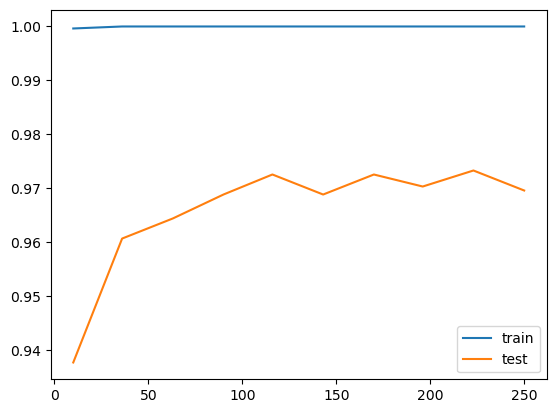

In [55]:
import matplotlib.pyplot as plt
plt.plot(n_estimators, train_scores.mean(axis=1), label='train')
plt.plot(n_estimators, test_scores.mean(axis=1), label='test')
plt.legend()
plt.show()

In [53]:
test_scores

array([[0.92592593, 0.94074074, 0.92565056, 0.95539033, 0.94052045],
       [0.98148148, 0.95555556, 0.94423792, 0.95910781, 0.96282528],
       [0.96296296, 0.95555556, 0.96654275, 0.96654275, 0.97026022],
       [0.96666667, 0.96666667, 0.97026022, 0.9739777 , 0.96654275],
       [0.97407407, 0.97037037, 0.9739777 , 0.97026022, 0.9739777 ],
       [0.97777778, 0.96666667, 0.9739777 , 0.96282528, 0.96282528],
       [0.97777778, 0.97037037, 0.96654275, 0.9739777 , 0.9739777 ],
       [0.97777778, 0.97037037, 0.96282528, 0.9739777 , 0.96654275],
       [0.97407407, 0.97407407, 0.9739777 , 0.9739777 , 0.97026022],
       [0.97407407, 0.96666667, 0.97026022, 0.97026022, 0.96654275]])

In [54]:
test_scores.mean(axis=1)

array([0.9376456 , 0.96064161, 0.96437285, 0.9688228 , 0.97253201,
       0.96881454, 0.97252926, 0.97029877, 0.97327275, 0.96956079])